# Bowtie Simulations

## Main design

In [1]:
import qiskit_metal
qiskit_metal.about()


Qiskit Metal        0.8.1

Basic
____________________________________
 Python              3.11.15 (main, May  4 2026, 21:17:00) [MSC v.1944 64 bit (AMD64)]
 Platform            Windows AMD64
 Installation path   C:\Users\DELL\chip-design\metal-flow\quantum-metal\src\qiskit_metal

Packages
____________________________________
 Numpy               1.26.4
 Qutip               5.3.0

Rendering
____________________________________
 Matplotlib          3.11.0

GUI
____________________________________
 PySide6 version     6.11.1
 Qt version          6.11.1
 SIP version         Not installed

IBM Quantum Team


'\nQiskit Metal        0.8.1\n\nBasic\n____________________________________\n Python              3.11.15 (main, May  4 2026, 21:17:00) [MSC v.1944 64 bit (AMD64)]\n Platform            Windows AMD64\n Installation path   C:\\Users\\DELL\\chip-design\\metal-flow\\quantum-metal\\src\\qiskit_metal\n\nPackages\n____________________________________\n Numpy               1.26.4\n Qutip               5.3.0\n\nRendering\n____________________________________\n Matplotlib          3.11.0\n\nGUI\n____________________________________\n PySide6 version     6.11.1\n Qt version          6.11.1\n SIP version         Not installed\n\nIBM Quantum Team'

In [2]:
# Cell 1 — Imports + design skeleton
from qiskit_metal import designs, draw, MetalGUI, Dict
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.pathfinder import RoutePathfinder

design = designs.DesignPlanar()
design.overwrite_enabled = True

design.chips.main.size['size_x'] = '11mm'
design.chips.main.size['size_y'] = '11mm'

design.chips.main.size['size_z'] = '-280um'
design.chips.main

{'material': 'silicon',
 'layer_start': '0',
 'layer_end': '2048',
 'size': {'center_x': '0.0mm',
  'center_y': '0.0mm',
  'center_z': '0.0mm',
  'size_x': '11mm',
  'size_y': '11mm',
  'size_z': '-280um',
  'sample_holder_top': '890um',
  'sample_holder_bottom': '1650um'}}

In [3]:
# Cell 2 (updated) — Q0–Q3 unchanged (TransmonPocket, 3 pads each fits the 4-corner limit).
# Q4 rebuilt as TransmonPocket6 with 5 angularly-placed connection pads.

from qiskit_metal.qlibrary.qubits.transmon_pocket_6 import TransmonPocket6


arm = "2 mm"


q0 = TransmonPocket(design, 'Q0', options=Dict(
    pos_x=f'-{arm}', pos_y=f'{arm}', orientation=90, pad_width='450 um', pad_height= "100 um", pad_gap = '20 um',
    connection_pads=Dict(
        to_Q4  =Dict(loc_W=-1, loc_H=-1),
        to_Q2  =Dict(loc_W=-1, loc_H=+1),
        readout=Dict(loc_W=+1, loc_H=+1),
    )))


q1 = TransmonPocket6(design, 'Q1', options=Dict(
    pos_x=f'{arm}', pos_y=f'{arm}',orientation=-90, pad_width='450 um', pad_height= "100 um", pad_gap = '20 um',
    connection_pads=Dict(
        readout=Dict(loc_W=-1, loc_H=+1),
        to_Q3  =Dict(loc_W=+1, loc_H=+1),
        to_Q4  =Dict(loc_W=+1, loc_H=-1),
    )))

q2 = TransmonPocket6(design, 'Q2', options=Dict(
    pos_x=f'-{arm}', pos_y=f'-{arm}',orientation=-90, pad_width='450 um', pad_height= "100 um", pad_gap = '20 um',
    connection_pads=Dict(
        readout=Dict(loc_W=+1, loc_H=-1),
        to_Q0  =Dict(loc_W=-1, loc_H=-1),
        to_Q4  =Dict(loc_W=-1, loc_H=+1),
    )))

q3 = TransmonPocket6(design, 'Q3', options=Dict(
    pos_x=f'{arm}', pos_y=f'-{arm}',orientation=90, pad_width='450 um', pad_height= "100 um", pad_gap = '20 um',
    connection_pads=Dict(
        readout=Dict(loc_W=-1, loc_H=-1),
        to_Q1  =Dict(loc_W=+1, loc_H=-1),
        to_Q4  =Dict(loc_W=+1, loc_H=+1),
    )))

# TransmonPocket6: connection_pads placed by angle (connector_location, degrees, CCW from +x).
# connector_type='0' = claw connector (matches TransmonPocket's pin style for routing).
q4 = TransmonPocket6(design, 'Q4', options=Dict(
    pos_x='0mm', pos_y='0mm', orientation=0, pad_width='450 um', pad_height= "100 um", pad_gap = '20 um',
    connection_pads=Dict(
        to_Q0  = Dict(loc_W=-1, loc_H=+1),
        to_Q1  = Dict(loc_W=+1, loc_H=+1),
        to_Q2  = Dict(loc_W=-1, loc_H=-1),
        to_Q3  = Dict(loc_W=+1, loc_H=-1),
        readout= Dict(loc_W=+0, loc_H=+1),
    )))

In [4]:
# Cell 4 (updated) — direct qubit-qubit couplers, now meandered instead of straight.
to_q4_meander_common = Dict(trace_width='10um', trace_gap='6um', fillet='69um',
                       meander=Dict(spacing='200um'),
                       lead=Dict(start_straight='600um', end_straight='0um'))




c02_jogsS = Dict()
c02_jogsS[0] = ["R", "300um"]

c02_jogsE = Dict()
c02_jogsE[0] = ["L", "300um"]

c02_meander_opts = Dict(
    advanced= Dict(avoid_collision= "true"),
    meander=Dict(spacing= "300um", asymmetry="-100um"),
    snap="true",
    lead= Dict(
        start_straight= "0.2mm",
        end_straight= "0.2mm",
        start_jogged_extension= c02_jogsS,
        end_jogged_extension= c02_jogsE,
    ),
    fillet='99 um',
)


c02 = RouteMeander(design, 'C02', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q0', pin='to_Q2'),
                     end_pin=Dict(component='Q2', pin='to_Q0')),
    total_length='10mm', **c02_meander_opts))




c13_jogsS = Dict()
c13_jogsS[0] = ["L", "300um"]

c13_jogsE = Dict()
c13_jogsE[0] = ["R", "300um"]

c13_meander_opts = Dict(
    advanced= Dict(avoid_collision= "true"),
    meander=Dict(spacing= "300um", asymmetry="100um"),
    snap="true",
    lead= Dict(
        start_straight= "0.2mm",
        end_straight= "0.2mm",
        start_jogged_extension= c13_jogsS,
        end_jogged_extension= c13_jogsE,
    ),
    fillet='99 um',
)


c13 = RouteMeander(design, 'C13', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q1', pin='to_Q3'),
                     end_pin=Dict(component='Q3', pin='to_Q1')),
    total_length='10mm', **c13_meander_opts))

c04 = RouteMeander(design, 'C04', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q0', pin='to_Q4'),
                     end_pin=Dict(component='Q4', pin='to_Q0')),
    total_length='10mm', asymmetry='0um', **to_q4_meander_common))

c41 = RouteMeander(design, 'C41', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q1', pin='to_Q4'),
                     end_pin=Dict(component='Q4', pin='to_Q1')),
    total_length='10mm', asymmetry='0um', **to_q4_meander_common))

c24 = RouteMeander(design, 'C24', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q2', pin='to_Q4'),
                     end_pin=Dict(component='Q4', pin='to_Q2')),
    total_length='10mm', asymmetry='0um', **to_q4_meander_common))

c43 = RouteMeander(design, 'C43', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q3', pin='to_Q4'),
                     end_pin=Dict(component='Q4', pin='to_Q3')),
    total_length='10mm', asymmetry='0um', **to_q4_meander_common))

# If you get a "total_length too short for meander" error, bump total_length up —
# it must exceed the straight-line pin-to-pin distance plus the lead lengths.

In [5]:
# Cell 5 (updated) — Launchpads (corrected orientation) + feedline built from
# LaunchpadWirebond -> CoupledLineTee -> CoupledLineTee -> LaunchpadWirebond.
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee

lp_opts = Dict(trace_width='10um', trace_gap='6um', lead_length='30um')

# Top pads face south (270deg) into the chip; bottom pads face north (90deg) into the chip.
tl0_in  = LaunchpadWirebond(design, 'TL_0_IN',  options=Dict(pos_x='-5mm', pos_y='5mm',  orientation='270', **lp_opts))
tl0_out = LaunchpadWirebond(design, 'TL_0_OUT', options=Dict(pos_x='-5mm', pos_y='-5mm', orientation='90',  **lp_opts))
tl1_in  = LaunchpadWirebond(design, 'TL_1_IN',  options=Dict(pos_x='5mm',  pos_y='5mm',  orientation='270', **lp_opts))
tl1_out = LaunchpadWirebond(design, 'TL_1_OUT', options=Dict(pos_x='5mm',  pos_y='-5mm', orientation='90',  **lp_opts))

tee_opts = Dict(prime_width='10um', prime_gap='6um',
                 second_width='10um', second_gap='6um',
                 coupling_space='4um', coupling_length='200um', fillet='49um')

# Left side: prime line runs vertically -> rotate tee 90deg so second_end points east (toward Q0/Q2, at x=-3).
clt_q0 = CoupledLineTee(design, 'CLT_Q0', options=Dict(pos_x='-5mm', pos_y='3mm',  orientation='90',  mirror=False, **tee_opts))
clt_q2 = CoupledLineTee(design, 'CLT_Q2', options=Dict(pos_x='-5mm', pos_y='-3mm', orientation='90',  mirror=False, **tee_opts))

# Right side: rotate tee -90deg so second_end points west (toward Q1/Q3, at x=3).
clt_q1 = CoupledLineTee(design, 'CLT_Q1', options=Dict(pos_x='5mm', pos_y='3mm',  orientation='270', mirror=False, **tee_opts))
clt_q3 = CoupledLineTee(design, 'CLT_Q3', options=Dict(pos_x='5mm', pos_y='-3mm', orientation='270', mirror=False, **tee_opts))

# After gui.rebuild(), check that each tee's coupled stub (second_end) points at its
# qubit, not away from it — if it's mirrored, flip mirror=True and re-rebuild.

feed_opts = Dict(trace_width='10um', trace_gap='6um', fillet='0um')

tl0_seg1 = RouteStraight(design, 'TL_0_seg1', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='TL_0_IN', pin='tie'),
                     end_pin=Dict(component='CLT_Q0', pin='prime_end')), **feed_opts))
tl0_seg2 = RouteStraight(design, 'TL_0_seg2', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='CLT_Q0', pin='prime_start'),
                     end_pin=Dict(component='CLT_Q2', pin='prime_end')), **feed_opts))
tl0_seg3 = RouteStraight(design, 'TL_0_seg3', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='CLT_Q2', pin='prime_start'),
                     end_pin=Dict(component='TL_0_OUT', pin='tie')), **feed_opts))

tl1_seg1 = RouteStraight(design, 'TL_1_seg1', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='TL_1_IN', pin='tie'),
                     end_pin=Dict(component='CLT_Q1', pin='prime_start')), **feed_opts))
tl1_seg2 = RouteStraight(design, 'TL_1_seg2', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='CLT_Q1', pin='prime_end'),
                     end_pin=Dict(component='CLT_Q3', pin='prime_start')), **feed_opts))
tl1_seg3 = RouteStraight(design, 'TL_1_seg3', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='CLT_Q3', pin='prime_end'),
                     end_pin=Dict(component='TL_1_OUT', pin='tie')), **feed_opts))

In [6]:
# Cell 6 (updated) — Resonators R0-R3: CoupledLineTee.second_end -> qubit.readout (meandered).
# R4: Q4's own 5th pad, left as an open (unconnected) resonator per our earlier assumption
# that the diagram doesn't show a feedline for Q4.

res_opts = Dict(trace_width='10um', trace_gap='6um', fillet='99um',
                 lead=Dict(start_straight='60um', end_straight='60um'))

r0 = RouteMeander(design, 'R0', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q0', pin='readout'),
                     end_pin=Dict(component='CLT_Q0', pin='second_end')),
    total_length='22mm', meander=Dict(spacing='200um', asymmetry='-700um'), **res_opts))

r1 = RouteMeander(design, 'R1', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q1', pin='readout'),
                     end_pin=Dict(component='CLT_Q1', pin='second_end')),
    total_length='22mm', meander=Dict(spacing='200um', asymmetry='700um'), **res_opts))

r2 = RouteMeander(design, 'R2', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q2', pin='readout'),
                     end_pin=Dict(component='CLT_Q2', pin='second_end')),
    total_length='22mm', meander=Dict(spacing='200um', asymmetry='700um'), **res_opts))

r3 = RouteMeander(design, 'R3', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q3', pin='readout'),
                     end_pin=Dict(component='CLT_Q3', pin='second_end')),
    total_length='22mm', meander=Dict(spacing='200um', asymmetry='-700um'), **res_opts))


r4_lp_opts = Dict(trace_width='10um', trace_gap='6um', lead_length='30um')

r4_lp = LaunchpadWirebond(design, 'r4_lp', options=Dict(pos_x='0mm',  pos_y='5mm', orientation='-90',  **r4_lp_opts))


r4 = RouteMeander(design, 'R4', options=Dict(
    pin_inputs=Dict(start_pin=Dict(component='Q4', pin='readout'),
                     end_pin=Dict(component='r4_lp', pin='tie')),
    total_length='22mm', trace_width='10um', trace_gap='6um', fillet='99um',
                 lead=Dict(start_straight='1500um', end_straight='0um')))

['Q0', 'Q1', 'Q2', 'Q3', 'Q4', 'C02', 'C13', 'C04', 'C41', 'C24', 'C43', 'TL_0_IN', 'TL_0_OUT', 'TL_1_IN', 'TL_1_OUT', 'CLT_Q0', 'CLT_Q2', 'CLT_Q1', 'CLT_Q3', 'TL_0_seg1', 'TL_0_seg2', 'TL_0_seg3', 'TL_1_seg1', 'TL_1_seg2', 'TL_1_seg3', 'R0', 'R1', 'R2', 'R3', 'r4_lp', 'R4']


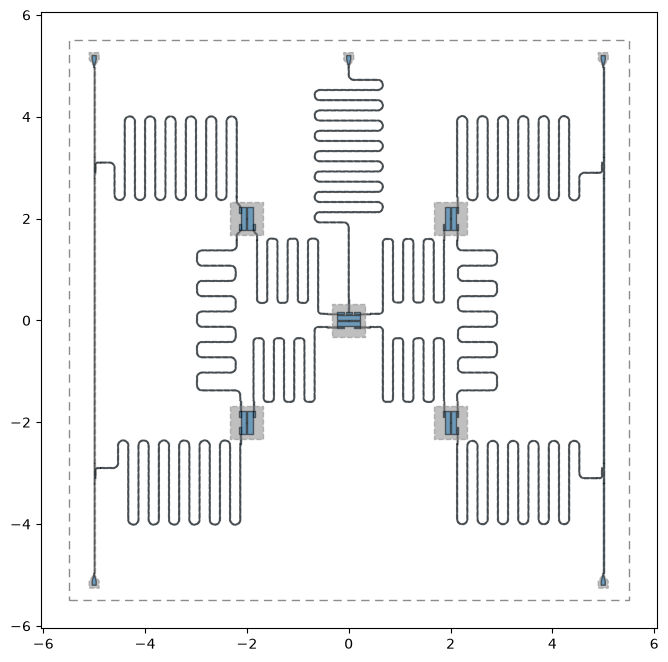

In [7]:
%matplotlib inline
from qiskit_metal import view
print(design.components.keys())
view(design)


## Graph 

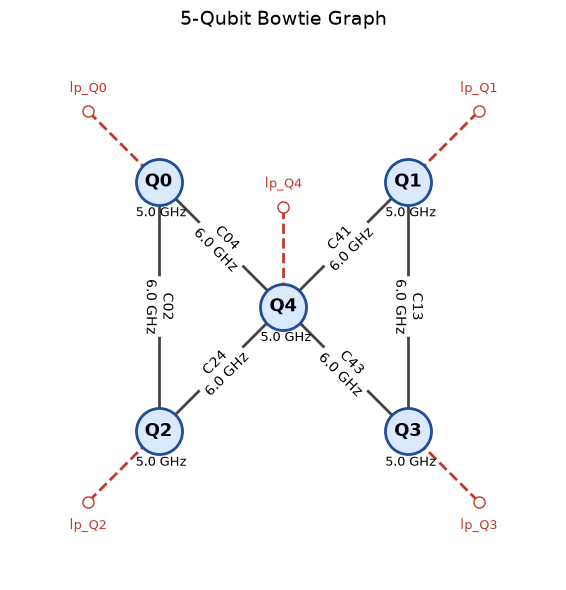

In [8]:
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# ---------- Graph: bowtie (two triangles sharing centre vertex C) ----------
G = nx.Graph()
G.add_nodes_from(["Q0", "Q2", "Q4", "Q1", "Q3"])

# (u, v, edge_label)
bowtie_edges = [
    ("Q0", "Q2", "C02"), ("Q2", "Q4", "C24"), ("Q0", "Q4", "C04"),   # left triangle
    ("Q4", "Q1", "C41"), ("Q1", "Q3", "C13"), ("Q4", "Q3", "C43"),   # right triangle
]
for u, v, lab in bowtie_edges:
    G.add_edge(u, v, label=lab)

# ---------- Dangling (unconnected) edges: one per vertex ----------
# Stored on the graph as node attributes; direction is a vector pointing away from the bowtie
stubs = {
    "Q0": ((-1,  1), "lp_Q0"),
    "Q2": ((-1, -1), "lp_Q2"),
    "Q4": (( 0,  1), "lp_Q4"),
    "Q1": (( 1,  1), "lp_Q1"),
    "Q3": (( 1, -1), "lp_Q3"),
}
for n, (direction, lab) in stubs.items():
    G.nodes[n]["stub_dir"] = direction
    G.nodes[n]["stub_label"] = lab

# ---------- Sublabels (fill these in; blank = reserved space) ----------
node_sublabels = {
                "Q0": "5.0 GHz",
                "Q2": "5.0 GHz",
                "Q4": "5.0 GHz",
                "Q1": "5.0 GHz",
                "Q3": "5.0 GHz",
                }
edge_sublabels = {("Q0", "Q2"): "6.0 GHz",
                  ("Q2", "Q4"): "6.0 GHz",
                  ("Q0", "Q4"): "6.0 GHz",
                  ("Q4", "Q1"): "6.0 GHz",
                  ("Q1", "Q3"): "6.0 GHz", 
                  ("Q4", "Q3"): "6.0 GHz"}
stub_sublabels = {n: "" for n in G.nodes}

# ---------- Layout ----------
pos = {"Q0": (-1, 1), "Q2": (-1, -1), "Q4": (0, 0), "Q1": (1, 1), "Q3": (1, -1)}

fig, ax = plt.subplots(figsize=(9, 6))

# Vertices and edges
nx.draw_networkx_edges(G, pos, ax=ax, width=2, edge_color="#444")
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=1100,
                       node_color="#dbe9ff", edgecolors="#1f4e99", linewidths=2)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=13, font_weight="bold")

# Vertex sublabels (below each node)
for n, (x, y) in pos.items():
    ax.text(x + 0.02, y - 0.20, node_sublabels[n] or " ", ha="center", va="top",
            fontsize=9, color="black")

# Edge labels + sublabel slot on a second line
edge_text = {(u, v): f"{lab}\n{edge_sublabels[(u, v)] or ' '}"
             for u, v, lab in bowtie_edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_text, ax=ax, font_size=10,
                             bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=1.0))

# Dangling edges (dashed, open end, labelled)
stub_len = 0.8
pad = 0.12
for n, (x, y) in pos.items():
    d = np.array(G.nodes[n]["stub_dir"], dtype=float)
    d /= np.linalg.norm(d)
    x2, y2 = x + stub_len * d[0], y + stub_len * d[1]
    ax.plot([x, x2], [y, y2], ls="--", lw=2, color="#c0392b", zorder=1)
    ax.plot(x2, y2, marker="o", ms=8, mfc="white", mec="#c0392b", zorder=2)  # open end
    lab, sub = G.nodes[n]["stub_label"], stub_sublabels[n] or " "
    if d[1] >= 0:   # stub points up -> text above the circle, label line nearest the circle
        txt, va, ty = f"{sub}\n{lab}", "bottom", y2 + pad
    else:           # stub points down -> text below the circle, label line nearest the circle
        txt, va, ty = f"{lab}\n{sub}", "top", y2 - pad
    ax.text(x2, ty, txt, ha="center", va=va, fontsize=9, color="#c0392b")

ax.set_title("5-Qubit Bowtie Graph", fontsize=14)
ax.set_aspect("equal")
ax.margins(0.2)
ax.axis("off")
plt.tight_layout()

## Nominal frequency and $\alpha$ calculations using LOM 

In [9]:
def edit_and_print_qubit_properties(design, qubit_name):

    design.components[qubit_name].options.pad_width = '500 um'
    design.components[qubit_name].options.pad_height = '100 um'
    design.components[qubit_name].options.pad_gap = '30 um'
    design.components[qubit_name].options.connection_pads.readout.pad_gap = '40 um'
    design.components[qubit_name].options.connection_pads.to_Q2.pad_gap = '30 um'
    design.components[qubit_name].options.connection_pads.to_Q4.pad_gap = '35 um'


    design.components[qubit_name].options.connection_pads.readout.pad_width = '70 um'
    design.components[qubit_name].options.connection_pads.to_Q2.pad_width = '70 um'
    design.components[qubit_name].options.connection_pads.to_Q4.pad_width = '70 um'

    print("-"*50)
    print(f"Capacitive tuninig {qubit_name}")
    print("-"*50)
    print(f"pad_width = {design.components[qubit_name].options.pad_width}\npad_height = {design.components[qubit_name].options.pad_height}\npad_gap = {design.components[qubit_name].options.pad_gap}")
    print("-"*50)

    for pin in design.components[qubit_name].pin_names:
        print(f"For pin {pin}")
        print(f"    pad_width = {design.components[qubit_name].options.connection_pads[pin].pad_width}")
        print(f"    pad_height = {design.components[qubit_name].options.connection_pads[pin].pad_height}")
        print(f"    pad_gap = {design.components[qubit_name].options.connection_pads[pin].pad_gap}")
        print("-"*50)

    design.rebuild()
    
    return None

In [10]:
from qiskit_metal.analyses import LOManalysis

lom = LOManalysis(design, 'q3d')

qubit_name = 'Q0'

sweep_setup = Dict(design = design,
                        # Only simulate q0 and define its open terminations to extract exact capacitance matrix
                        run_args_dict = Dict(components=[design.components[qubit_name].name] , open_terminations=[(design.components[qubit_name].name, pad) for pad in design.components[qubit_name].pins.keys()], box_plus_buffer=True),
                        # LOM physics constraints (Josephson Junction Inductance & Capacitance)
                        lom_setup = Dict(junctions=Dict(Lj=11.5, Cj=2), freq_readout=[6.9], freq_bus=[6.0, 6.5]),
                        # Ansys Q3D Iterative solver properties
                        lom_sim_setup = Dict(name = f'{qubit_name}_setup', 
                                             reuse_selected_design = True, 
                                             reuse_setup = True,
                                             freq_ghz = 5.2,
                                             save_fields = True, 
                                             enabled = True, 
                                             max_passes = 35, 
                                             min_passes = 2, 
                                             min_converged_passes = 2, 
                                             percent_error = 1,#0.05, 
                                             percent_refinement = 30, 
                                             auto_increase_solution_order = True, 
                                             solution_order = 'Highest', 
                                             solver_type = 'Iterative',
                                             ))



print(edit_and_print_qubit_properties(design, qubit_name))

lom.sim.setup = sweep_setup.lom_sim_setup
lom.setup = sweep_setup.lom_setup

lom.sim.run(**sweep_setup.run_args_dict)



--------------------------------------------------
Capacitive tuninig Q0
--------------------------------------------------
pad_width = 500 um
pad_height = 100 um
pad_gap = 30 um
--------------------------------------------------
For pin to_Q2
    pad_width = 70 um
    pad_height = 30um
    pad_gap = 30 um
--------------------------------------------------
For pin to_Q4
    pad_width = 70 um
    pad_height = 30um
    pad_gap = 35 um
--------------------------------------------------
For pin readout
    pad_width = 70 um
    pad_height = 30um
    pad_gap = 40 um
--------------------------------------------------
None


INFO 05:14PM [connect_project]: Connecting to Ansys Desktop API...
INFO 05:14PM [load_ansys_project]: 	Opened Ansys App
INFO 05:14PM [load_ansys_project]: 	Opened Ansys Desktop v2025.2.0
INFO 05:14PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/DELL/Documents/Ansoft/
	Project:   Project10
INFO 05:14PM [connect_design]: No active design found (or error getting active design).
INFO 05:14PM [connect]: 	 Connected to project "Project10". No design detected
INFO 05:14PM [connect_design]: 	Opened active design
	Design:    Design_q3d [Solution type: Q3D]
WARNING 05:14PM [connect_setup]: 	No design setup detected.
WARNING 05:14PM [connect_setup]: 	Creating Q3D default setup.
INFO 05:14PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 05:14PM [get_setup]: 	Opened setup `Q0_setup`  (<class 'pyEPR.ansys.AnsysQ3DSetup'>)
INFO 05:14PM [analyze]: Analyzing setup Q0_setup
INFO 05:15PM [get_matrix]: Exporting matrix data to (C:\Users\DELL\AppData\Loc

In [22]:
# lom.setup = Dict(junctions=Dict(Lj=11.5, Cj=2), freq_readout=[7.0], freq_bus=[6.0, 6.2])
lom.run_lom()

[3, 4] [5 0 1]
Predicted Values

Transmon Properties
f_Q 8.215086 [GHz]
EC 712.830706 [MHz]
EJ 14.202584 [GHz]
alpha -933.828932 [MHz]
dispersion 12569.756815 [KHz]
Lq 11.500000 [nH]
Cq 27.173672 [fF]
T1 42536.080881 [us]

**Coupling Properties**

tCqbus1 -0.093721 [fF]
gbus1_in_MHz -2.795513 [MHz]
χ_bus1 -0.029178 [MHz]
1/T1bus1 3.684057 [Hz]
T1bus1 43200.997296 [us]

tCqbus2 0.054584 [fF]
gbus2_in_MHz 1.399564 [MHz]
χ_bus2 -0.001308 [MHz]
1/T1bus2 0.031999 [Hz]
T1bus2 4973701.490705 [us]

tCqbus3 0.034380 [fF]
gbus3_in_MHz 0.963782 [MHz]
χ_bus3 -0.001303 [MHz]
1/T1bus3 0.025589 [Hz]
T1bus3 6219607.140205 [us]
Bus-Bus Couplings
gbus1_2 75.948742 [MHz]
gbus1_3 34.916067 [MHz]
gbus2_3 91.410298 [MHz]


,fQ,EC,EJ,alpha,dispersion,gbus,chi_in_MHz,χr MHz,gr MHz
1,9.110728,901.213943,14.202584,-1254.995379,45769.690347,"[-5.895949693315172, -13.24057002817657, 20.53...","[-0.041665343098605305, -0.07832858725841166, ...",0.041665,5.895950
2,8.76458,824.95662,14.202584,-1121.08183,28690.510797,"[-3.354264165209784, 0.5872541932830293, 1.280...","[-0.018307796051854435, -0.0001740236411785778...",0.018308,3.354264
3,8.635427,797.640063,14.202584,-1074.337661,23863.582868,"[-2.9850001280417833, 0.9222550889866412, 0.97...","[-0.01677278162932158, -0.000453424088613284, ...",0.016773,2.985000
4,8.551966,780.307108,14.202584,-1045.042916,21120.572452,"[-3.0902484241052517, 0.7356920492914867, 1.13...","[-0.01999712660249958, -0.00029991990159958774...",0.019997,3.090248
5,8.492358,768.079387,14.202584,-1024.552126,19327.301006,"[-2.970166745421313, 1.5276460184189138, 0.925...","[-0.020075086617558868, -0.0013316661501659123...",0.020075,2.970167
6,8.430766,755.576231,14.202584,-1003.752352,17610.132839,"[-2.9130080165580803, 0.6452411070964107, 1.05...","[-0.021193466582914527, -0.0002452649902559703...",0.021193,2.913008
7,8.40506,750.397259,14.202584,-995.182427,16932.340104,"[-2.888597934806426, 1.2690143774034843, 0.951...","[-0.021717326054399928, -0.0009618687930367461...",0.021717,2.888598
8,8.372445,743.859443,14.202584,-984.402354,16104.02372,"[-2.8668777516436577, 1.3842563764860132, 0.97...","[-0.022591833643389486, -0.0011652152428959302...",0.022592,2.866878
9,8.34474,738.334589,14.202584,-975.326076,15427.378634,"[-2.849743911714665, 1.4623721478277592, 0.941...","[-0.023431386226706215, -0.0013209226266499873...",0.023431,2.849744
10,8.315018,732.437263,14.202584,-965.67192,14728.245882,"[-2.8358800000158517, 1.4940802058409544, 0.96...","[-0.024499857498601247, -0.0014027208800819182...",0.024500,2.835880


In [ ]:
lom.sim.capacitance_matrix

In [11]:
lom.run_lom()

[3, 4] [5 0 1]
Predicted Values

Transmon Properties
f_Q 9.225718 [GHz]
EC 927.557569 [MHz]
EJ 14.202584 [GHz]
alpha -1302.281690 [MHz]
dispersion 53023.472023 [KHz]
Lq 11.500000 [nH]
Cq 20.883047 [fF]
T1 88216.856054 [us]

**Coupling Properties**

tCqbus1 -0.041692 [fF]
gbus1_in_MHz -1.558243 [MHz]
χ_bus1 -0.002683 [MHz]
1/T1bus1 0.405534 [Hz]
T1bus1 392457.278332 [us]

tCqbus2 0.400925 [fF]
gbus2_in_MHz 12.851004 [MHz]
χ_bus2 -0.071356 [MHz]
1/T1bus2 1.398548 [Hz]
T1bus2 113800.145679 [us]

tCqbus3 0.001855 [fF]
gbus3_in_MHz 0.064933 [MHz]
χ_bus3 -0.000003 [MHz]
1/T1bus3 0.000051 [Hz]
T1bus3 3134013074.075130 [us]
Bus-Bus Couplings
gbus1_2 68.385245 [MHz]
gbus1_3 16.184470 [MHz]
gbus2_3 107.006159 [MHz]


,fQ,EC,EJ,alpha,dispersion,gbus,chi_in_MHz,χr MHz,gr MHz
1,9.706767,1043.508808,14.202584,-1514.68772,94337.719109,"[-0.16897083906068947, 14.554896583930983, -14...","[-2.4194693400858256e-05, -0.08185945576630631...",0.000024,0.168971
2,9.584406,1013.112349,14.202584,-1458.515999,81944.919044,"[-1.7874395336968603, 13.221799626540564, -2.4...","[-0.0028696982204626854, -0.06923771990410182,...",0.002870,1.787440
3,9.42956,975.539103,14.202584,-1389.481886,68193.831483,"[-1.692613978951096, 14.312387294286621, -0.11...","[-0.0027933330913830472, -0.08398978307357854,...",0.002793,1.692614
4,9.372787,962.008495,14.202584,-1364.767986,63651.272382,"[-1.654964729331122, 14.428956215923774, -0.38...","[-0.002759367747536288, -0.08654662485799725, ...",0.002759,1.654965
5,9.310789,947.38042,14.202584,-1338.153959,58976.476282,"[-1.6093154294927539, 13.292568505858888, -0.0...","[-0.0027091972413369504, -0.07461663209747227,...",0.002709,1.609315
6,9.245388,932.115576,14.202584,-1310.509162,54354.005693,"[-1.5699521040978563, 12.759506805026845, 0.07...","[-0.0026885458477082214, -0.06996297875990358,...",0.002689,1.569952
7,9.225718,927.557569,14.202584,-1302.28169,53023.472023,"[-1.558243482703017, 12.851004449566453, 0.064...","[-0.0026834320976364032, -0.07135638932920707,...",0.002683,1.558243


In [ ]:
lom.lumped_oscillator

In [26]:
lom.sim.close()

NameError: name 'lom' is not defined

In [25]:
del lom